In [15]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from IPython.display import display

video_path = Path(r"C:\Users\lenovo\Desktop\CV_Assignment.ipynb\video\video1.mp4")

if not video_path.exists():
    raise FileNotFoundError(f"Video not found: {video_path}")

project_folder = video_path.parent.parent
output_folder = project_folder / "task3_outputs"
frames_folder = output_folder / "frames"

frames_folder.mkdir(parents=True, exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("Video exists:", video_path.exists())
print("Video path:", video_path)
print("Output folder:", output_folder)

OpenCV version: 4.10.0
Video exists: True
Video path: C:\Users\lenovo\Desktop\CV_Assignment.ipynb\video\video1.mp4
Output folder: C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs


In [16]:
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise ValueError("Unable to open the video file.")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
duration = total_frames / fps if fps > 0 else 0

print("Total frames:", total_frames)
print("Frames per second:", fps)
print("Video duration:", round(duration, 2), "seconds")

frame_positions = np.linspace(
    0, max(total_frames - 1, 0), min(5, total_frames), dtype=int
)

extracted_frames = []

for i, position in enumerate(frame_positions):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(position))
    success, frame = cap.read()

    if success:
        frame_file = frames_folder / f"frame_{i + 1}.jpg"
        cv2.imwrite(str(frame_file), frame)
        extracted_frames.append(frame_file)

cap.release()

print("Frames extracted:", len(extracted_frames))

Total frames: 330
Frames per second: 25.0
Video duration: 13.2 seconds
Frames extracted: 5


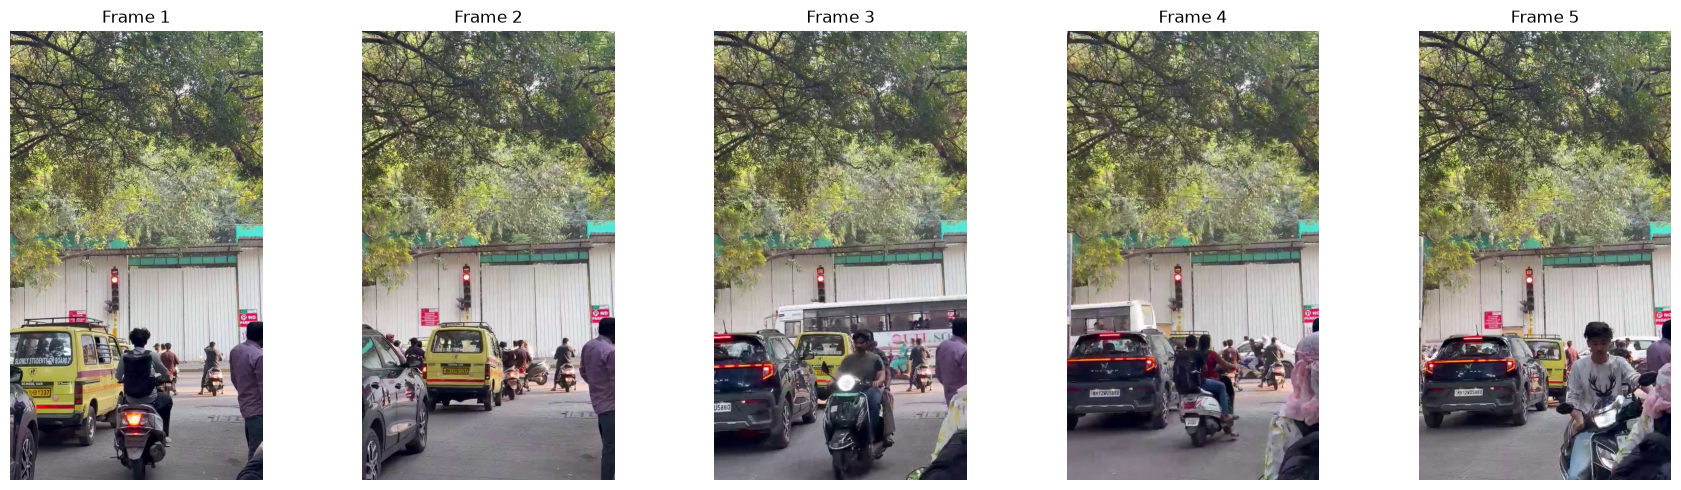

In [17]:
fig, axes = plt.subplots(
    1, len(extracted_frames), figsize=(18, 5)
)

if len(extracted_frames) == 1:
    axes = [axes]

for i, frame_file in enumerate(extracted_frames):
    frame = cv2.imread(str(frame_file))
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    axes[i].imshow(frame_rgb)
    axes[i].set_title(f"Frame {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

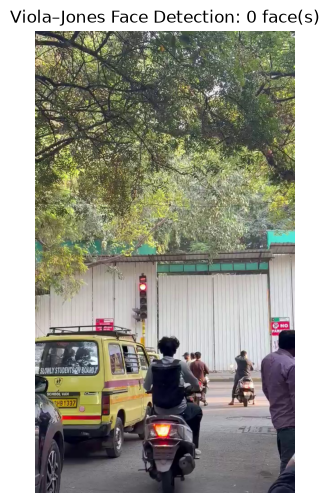

Faces detected: 0


In [18]:
haar_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(haar_path)

if face_cascade.empty():
    raise ValueError("Unable to load the Haar Cascade classifier.")

selected_frame_path = extracted_frames[0]
original_frame = cv2.imread(str(selected_frame_path))

gray_frame = cv2.cvtColor(original_frame, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(
    gray_frame,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

viola_frame = original_frame.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        viola_frame,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(viola_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Viola–Jones Face Detection: {len(faces)} face(s)")
plt.axis("off")
plt.show()

print("Faces detected:", len(faces))

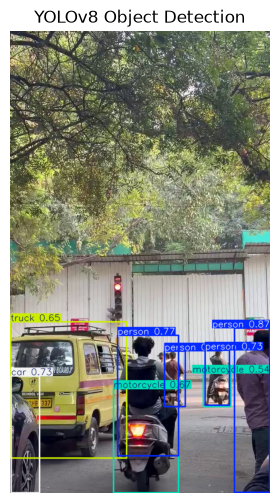

Objects detected: 8


In [19]:
model = YOLO("yolov8n.pt")

yolo_results = model.predict(
    source=str(selected_frame_path),
    conf=0.25,
    verbose=False
)

result = yolo_results[0]
yolo_frame = result.plot()

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(yolo_frame, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8 Object Detection")
plt.axis("off")
plt.show()

print("Objects detected:", len(result.boxes))

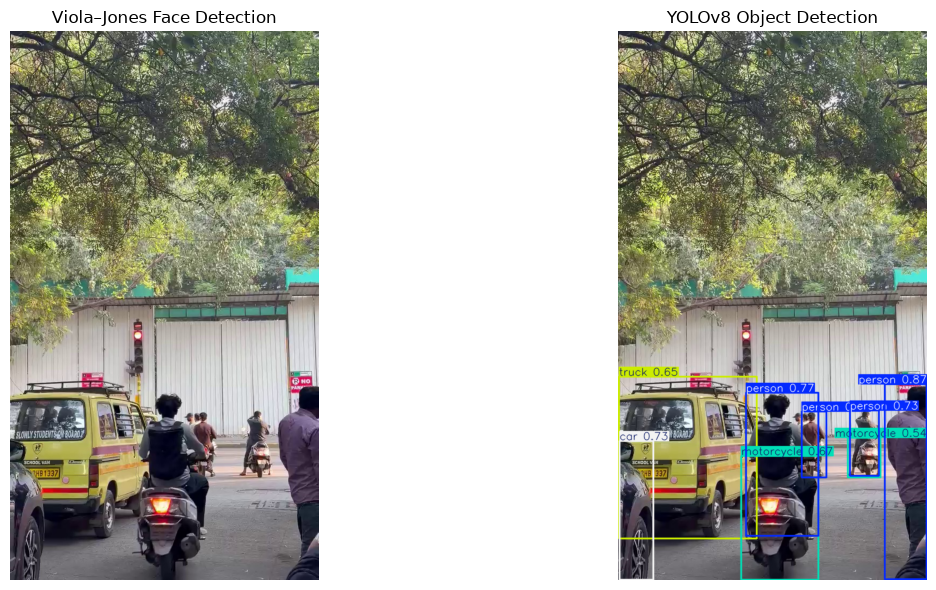

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(cv2.cvtColor(viola_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Viola–Jones Face Detection")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(yolo_frame, cv2.COLOR_BGR2RGB))
axes[1].set_title("YOLOv8 Object Detection")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [21]:
detection_data = []

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    detection_data.append({
        "Object": model.names[class_id],
        "Confidence": round(confidence, 3),
        "X1": x1,
        "Y1": y1,
        "X2": x2,
        "Y2": y2
    })

detection_df = pd.DataFrame(
    detection_data,
    columns=["Object", "Confidence", "X1", "Y1", "X2", "Y2"]
)

display(detection_df)

,Object,Confidence,X1,Y1,X2,Y2
0,person,0.869,497,658,575,1022
1,person,0.774,238,674,373,941
2,person,0.731,432,707,486,829
3,car,0.730,2,764,65,1023
4,person,0.705,342,709,388,832
5,motorcycle,0.674,229,792,373,1023
6,truck,0.646,1,644,258,946
7,motorcycle,0.539,428,758,489,832


In [22]:
comparison_df = pd.DataFrame({
    "Method": ["Viola–Jones", "YOLOv8"],
    "Purpose": [
        "Face detection",
        "Detection of multiple object classes"
    ],
    "Detections": [
        len(faces),
        len(result.boxes)
    ],
    "Approach": [
        "Haar Cascade classifier",
        "Pretrained deep learning model"
    ]
})

display(comparison_df)

,Method,Purpose,Detections,Approach
0,Viola–Jones,Face detection,0,Haar Cascade classifier
1,YOLOv8,Detection of multiple object classes,8,Pretrained deep learning model


In [23]:
all_detections = []

for frame_number, frame_file in enumerate(extracted_frames, start=1):
    predictions = model.predict(
        source=str(frame_file),
        conf=0.25,
        verbose=False
    )

    frame_result = predictions[0]

    for box in frame_result.boxes:
        class_id = int(box.cls[0])

        all_detections.append({
            "Frame": frame_number,
            "Object": model.names[class_id],
            "Confidence": round(float(box.conf[0]), 3)
        })

all_detections_df = pd.DataFrame(
    all_detections,
    columns=["Frame", "Object", "Confidence"]
)

display(all_detections_df)

,Frame,Object,Confidence
0,1,person,0.869
1,1,person,0.774
2,1,person,0.731
3,1,car,0.730
4,1,person,0.705
5,1,motorcycle,0.674
6,1,truck,0.646
7,1,motorcycle,0.539
8,2,car,0.891
9,2,person,0.880


In [24]:
viola_output = output_folder / "viola_jones_result.jpg"
yolo_output = output_folder / "yolo_result.jpg"
detection_csv = output_folder / "yolo_detections.csv"
comparison_csv = output_folder / "method_comparison.csv"
all_frames_csv = output_folder / "all_frame_detections.csv"

cv2.imwrite(str(viola_output), viola_frame)
cv2.imwrite(str(yolo_output), yolo_frame)

detection_df.to_csv(detection_csv, index=False)
comparison_df.to_csv(comparison_csv, index=False)
all_detections_df.to_csv(all_frames_csv, index=False)

print("All results saved successfully.")
print("Output folder:", output_folder)

for file in output_folder.rglob("*"):
    if file.is_file():
        print(file)

All results saved successfully.
Output folder: C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\all_frame_detections.csv
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\method_comparison.csv
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\original_image.png
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\viola_jones_result.jpg
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\yolo_detections.csv
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\yolo_result.jpg
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\frames\frame_1.jpg
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\frames\frame_2.jpg
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\frames\frame_3.jpg
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\frames\frame_4.jpg
C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task3_outputs\frames\frame_5.jpg


## Comparison and Conclusion

Viola–Jones uses a Haar Cascade classifier to detect faces, whereas YOLOv8 uses a pretrained deep learning model to detect multiple object classes. YOLOv8 displays bounding boxes, object labels and confidence scores, while the Viola–Jones output highlights detected faces. The results show the differences in the purpose and detection capabilities of the two approaches. Detection performance depends on image quality, object visibility and the capabilities of the selected model.


### Missed or Incorrect Detection Analysis

The detection outputs were visually inspected for missed objects and incorrect detections. Any missed or incorrect detection should be reported only when it is clearly visible in the results. Detection performance may vary depending on object visibility, image quality and model limitations.
